# MillionTrees — TreePoints mini dataloader & evaluation smoke workflow

**Paper**: *MillionTrees: A global benchmark for tree detection across geography, sensor, and annotation geometry* — bioRxiv preprint v1 (posted 2026-11-02), DOI [10.64898/2026.10.30.762845](https://doi.org/10.64898/2026.10.30.762845)
**Code**: [weecology/MillionTrees](https://github.com/weecology/MillionTrees) @ commit `b6ebe7ecb53e56be7b036566b9e101aca49176f5` (package version 0.12.0, MIT license; authors B. Weinstein, H. Senyondo, E. White — weecology)

## Scope and execution status
- **Executed scope (PARTIAL demonstration)**: the paper's documented dataloader + evaluation smoke workflow on the **TreePoints** mini release (`MiniTreePoints_v0.25.zip`, 30 images, 5,348 point annotations), following `docs/getting_started.md` and `docs/evaluation.md` at the pinned commit.
- **Not executed / out of scope**: full 355 GB benchmark releases, model training, fine-tuned model inference (the repository publishes no paper-matched trained checkpoints — its `weights/` directory contains only a DeepForest loader script), and benchmark-level metrics. This notebook validates the *data/eval infrastructure* the paper describes, not its published accuracy numbers.
- **Execution status**: fully executed on a fresh Google Colab **CPU** runtime (see final cells for the validation record).

## 実行内容（日本語）
- 論文「MillionTrees」の公式 Python パッケージ（指定コミット）を Colab にインストールし、TreePoints ミニ版（30 枚・5,348 点のアノテーション）をダウンロードします。
- 論文ドキュメントに記載されたデータローダ（`get_train_loader` / `get_eval_loader`）と評価 API（`dataset.eval`）を、正解アノテーションを「完璧な予測」として投入するスモークテストで検証します。
- フルベンチマーク（355 GB）・学習・推論は範囲外です。リポジトリに学習済みチェックポイントは公開されていません。

## Documented compatibility adaptation
**Python 3.13**: Colab's runtime is Python 3.13 while `milliontrees` metadata pins `requires-python <3.13`. The package is pure Python; it is installed from the **pinned commit** with `--ignore-requires-python` and verified (source-file SHA-256 printed below). The authors' `<3.13` pin is conservative, but this is a deviation from the author metadata — noted here explicitly. Dataset selection uses the authors' own `version=0.25` API (the pinned code's versions dict already contains 0.25; its code comment notes older v0.18–v0.23 archives were pruned from the server). 作成者コードへのパッチは行っていません。

## Runtime selection
This workflow is **CPU-only**: it exercises the dataloader, image decoding, and metric computation on a 155 MB mini archive. No model inference or CUDA operations exist in this scope, so **no GPU is needed** — select *Runtime → Change runtime type → CPU* (the default is fine). Expected duration: ~4–8 minutes total (install ~2–4 min, download ~0.5 min, analysis ~1–2 min); expected downloads: ~155 MB dataset + a few MB of packages.

**実行環境**: CPU のみで動作します（モデル推論・GPU 処理は含みません）。所要時間の目安は全体で 4〜8 分、ダウンロードは約 155 MB です。

## 1. Environment setup
Install the authors' package **from the pinned commit** (`--no-deps` so Colab's preinstalled torch stack is reused; all declared dependencies are already satisfied on Colab except the small pure-Python `milliontrees` extras). Python 3.13 compatibility adaptation as declared above.

パッケージを論文調査時に特定したコミット（`b6ebe7e`）からインストールします。Colab は Python 3.13 のため `--ignore-requires-python` を使用します（純 Python パッケージであり、動作は後続セルで検証します）。

In [ ]:
import sys, subprocess, hashlib, urllib.request

COMMIT = 'b6ebe7ecb53e56be7b036566b9e101aca49176f5'
RAW = (f'https://raw.githubusercontent.com/weecology/MillionTrees/{COMMIT}'
       '/src/milliontrees/datasets/TreePoints.py')
r = subprocess.run([sys.executable, '-m', 'pip', 'install', '--ignore-requires-python',
                    '--force-reinstall', '--no-deps', '-q',
                    f'https://github.com/weecology/MillionTrees/archive/{COMMIT}.tar.gz'],
                   capture_output=True, text=True, timeout=1800)
print('pip returncode:', r.returncode)
if r.returncode != 0:
    print(r.stderr[-1500:]); raise RuntimeError('milliontrees install failed')

pip returncode: 0


Verify the install: package version must be 0.12.0 and the installed `TreePoints.py` must be byte-identical (SHA-256) to the pinned commit's file on GitHub — this proves the adaptation did not alter the authors' code.

インストール検証：パッケージ VERSION が 0.12.0 であること、インストールされた `TreePoints.py` の SHA-256 が GitHub 上の指定コミットのファイルと一致することを確認します。

In [ ]:
import milliontrees, inspect, milliontrees.datasets.TreePoints as tp_mod

expected_sha = hashlib.sha256(urllib.request.urlopen(RAW, timeout=60).read()).hexdigest()
installed_sha = hashlib.sha256(open(inspect.getsourcefile(tp_mod), 'rb').read()).hexdigest()
print('milliontrees version:', milliontrees.__version__)
print('pinned  TreePoints.py sha256:', expected_sha)
print('installed TreePoints.py sha256:', installed_sha)
assert milliontrees.__version__ == '0.12.0'
assert expected_sha == installed_sha, 'installed source does not match pinned commit'
print('OK: installed source is byte-identical to pinned commit', COMMIT[:12])

milliontrees version: 0.12.0
pinned  TreePoints.py sha256: 12a3a1b964329d0be6c46c6e41d6ad074b987fce7ded3fb0f2eea966d9bfe114
installed TreePoints.py sha256: 12a3a1b964329d0be6c46c6e41d6ad074b987fce7ded3fb0f2eea966d9bfe114
OK: installed source is byte-identical to pinned commit b6ebe7ecb53e


Print the environment details for the validation record (Python, torch, device). Torch is used by the package for tensors and loaders only — no GPU is required.

検証記録のため、Python・torch・デバイスの情報を表示します（本デモは CPU のみ使用）。

In [ ]:
import torch, platform
print('Python:', platform.python_version())
print('torch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device used in this notebook:', device, '(CPU is sufficient for this workflow)')

Python: 3.13.18
torch: 2.14.1+cpu | CUDA available: False
device used in this notebook: cpu (CPU is sufficient for this workflow)


## 2. Download the TreePoints mini release
`get_dataset('TreePoints', download=True, mini=True)` with the package's own `version=` API. Version **0.25** is requested explicitly: it is the current dataset release referenced by the pinned commit (its versions dict contains 0.25), and the mini archive `MiniTreePoints_v0.25.zip` (155,178,905 bytes, HTTP 200 verified) is hosted on the authors' server. Older mini archives (v0.18–v0.23) were pruned server-side, as noted in the authors' own code comment. No author code is modified.

パッケージの `version=` API で現行リリース v0.25 を明示指定します（指定コミットのバージョン辞書に存在。古いミニアーカイブはサーバーから削除済みのため、著者コードのコメントにも記載があります）。作成者コードへのパッチは行いません。

In [ ]:
import time
from milliontrees import get_dataset
import milliontrees.datasets.TreePoints as tp_mod

print('pinned versions dict keys:', sorted(tp_mod.TreePointsDataset._versions_dict.keys()))
t0 = time.time()
dataset = get_dataset('TreePoints', version=0.25, download=True, mini=True, root_dir='/content/milliontrees_data')
print('download + extract + load: %.1f s' % (time.time() - t0))
print('data dir:', dataset._data_dir)

pinned versions dict keys: ['0.0', '0.24', '0.25']


0Byte [00:00, ?Byte/s]

  0%|          | 0/155178905 [00:00<?, ?Byte/s]

  0%|          | 606208/155178905 [00:00<00:25, 6059543.09Byte/s]

  6%|▌         | 8790016/155178905 [00:00<00:02, 49365523.23Byte/s]

  8%|▊         | 12566528/155178905 [00:03<00:50, 2844413.98Byte/s]

... (58 outputs left out)

155181056Byte [00:45, 3378954.19Byte/s]                             

Extracting /content/milliontrees_data/MiniTreePoints_v0.25/archive.zip to /content/milliontrees_data/MiniTreePoints_v0.25



It took 0.79 minutes to download and uncompress the dataset.



[MillionTrees] Loaded TreePoints v0.25 (mini)
[MillionTrees] Data dir: /content/milliontrees_data/MiniTreePoints_v0.25
[MillionTrees] Split: within-distribution | Images train/test/total: 26/4/30
[MillionTrees] Annotations: 5348 | Sources selected/available: 10/12
[MillionTrees] exclude_sources: ['*unsupervised*']
download + extract + load: 47.7 s
data dir: /content/milliontrees_data/MiniTreePoints_v0.25


Inspect what was loaded: split counts, annotation count, source count, and the annotation DataFrame columns (as documented in `docs/dataset_structure.md`: `filename`, `x`, `y`, `source`, `split`, `source_id`, `filename_id`).

読み込まれたデータの規模（分割数・アノテーション数・ソース数）と DataFrame の列を確認します。

In [ ]:
print('items:', len(dataset))
print('split sizes:', {s: int((dataset.split_array == v).sum()) for s, v in dataset.split_dict.items()})
print('annotation rows:', len(dataset.df), '| columns:', list(dataset.df.columns)[:12], '...')
print('sources:', dataset.df['source'].nunique())
print('source names:', sorted(dataset.df['source'].unique()))
dataset.df[['filename', 'x', 'y', 'source', 'split']].head(5)

items: 30
split sizes: {'train': 26, 'validation': 0, 'test': 4}
annotation rows: 5348 | columns: ['Unnamed: 0', 'x', 'y', 'label', 'source', 'filename', 'existing_split', 'geometry', 'split', 'score', 'genus', 'taxonomy_id'] ...
sources: 10
source names: ['Allen et al. 2025', 'Amirkolaee et al. 2023', 'Chen & Shang (2022)', 'Dubrovin et al. 2024', 'Frey et al. 2026', 'NEON MultiTemporal', 'NEON_points', 'OFO field 2025', 'OSBS megaplot 2025', 'Ventura et al. 2022']


,filename,x,y,source,split
0,long_beach_2018_92_Ventura_et_al_2022.tif,143.0,224.0,Ventura et al. 2022,train
1,long_beach_2018_92_Ventura_et_al_2022.tif,7.0,219.0,Ventura et al. 2022,train
2,long_beach_2018_92_Ventura_et_al_2022.tif,195.0,198.0,Ventura et al. 2022,train
3,long_beach_2018_92_Ventura_et_al_2022.tif,182.0,215.0,Ventura et al. 2022,train
4,long_beach_2018_92_Ventura_et_al_2022.tif,128.0,246.0,Ventura et al. 2022,train


## 3. Input preview — images with their ground-truth point annotations
Before any analysis, view the actual sample data. Two images from different sources are rendered with their **ground-truth tree-centroid annotations** (purple crosses) taken directly from the package's annotation DataFrame — real author annotations, not synthetic overlays.

サンプル画像と、作者による正解ポイント（紫の ×）を重ねて表示します。アノテーションはパッケージの DataFrame から取得した実データです。

previewing: ['000089_ortho_271_OFO_field_2025.png', 'eureka_2020_16_Ventura_et_al_2022.tif']


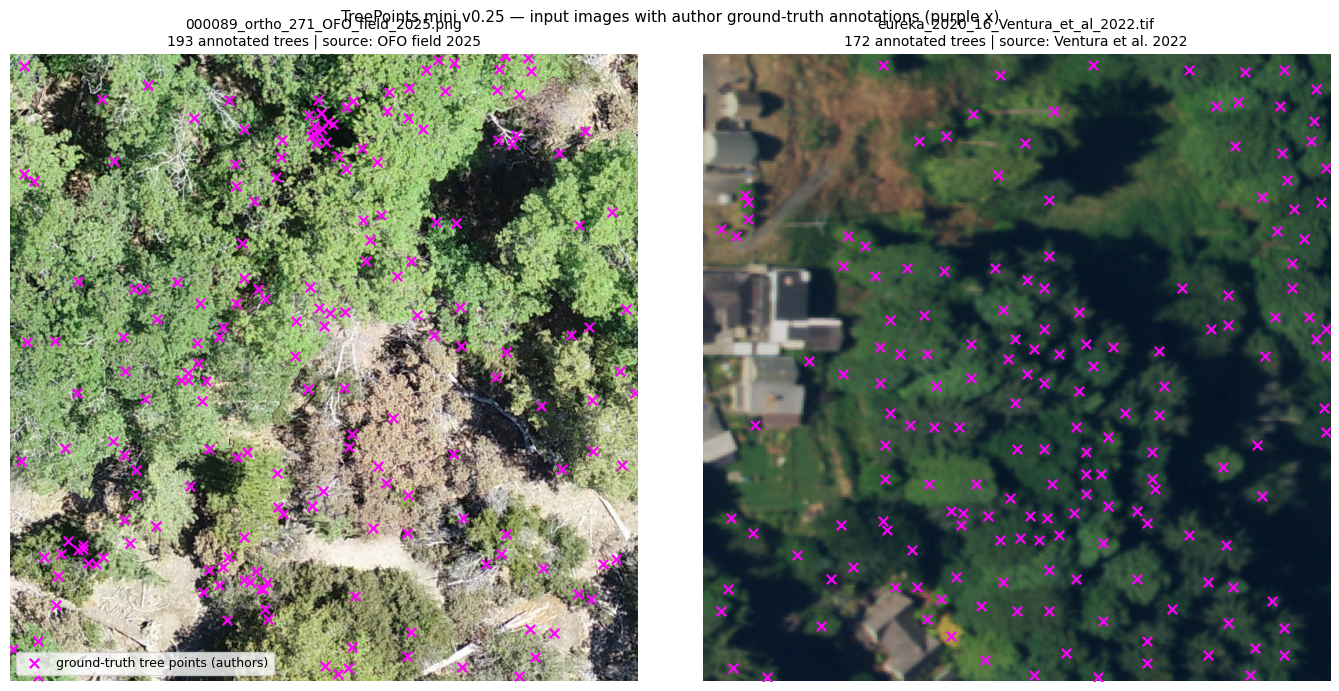

saved /content/treepoints_input_preview.png


In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

img_dir = Path(str(dataset._data_dir)) / 'images'
files = sorted(dataset.df['filename'].unique())
picks = [files[0], files[len(files) // 2]]
print('previewing:', picks)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, fname in zip(axes, picks):
    img = Image.open(img_dir / fname).convert('RGB')
    pts = dataset.df[dataset.df['filename'] == fname]
    ax.imshow(img)
    ax.scatter(pts['x'], pts['y'], s=46, marker='x', c='magenta', linewidths=1.6, label='ground-truth tree points (authors)')
    ax.set_title(f'{fname}\n{len(pts)} annotated trees | source: {pts["source"].iloc[0]}', fontsize=10)
    ax.axis('off')
axes[0].legend(loc='lower left', fontsize=9)
plt.suptitle('TreePoints mini v0.25 — input images with author ground-truth annotations (purple x)', fontsize=11)
plt.tight_layout()
plt.savefig('/content/treepoints_input_preview.png', dpi=110, bbox_inches='tight')
plt.show()
print('saved /content/treepoints_input_preview.png')

Basic image/annotation statistics per source: image sizes vary by sensor (drone ortho, aerial, field photos) — this diversity is the core motivation of the benchmark paper.

ソースごとの画像サイズとアノテーション数のばらつきを確認します（センタ多様性が本ベンチマークの主眼です）。

In [ ]:
rows = []
for fname in sorted(dataset.df['filename'].unique()):
    with Image.open(img_dir / fname) as im:
        w, h = im.size
    n = int((dataset.df['filename'] == fname).sum())
    rows.append((fname, dataset.df[dataset.df['filename'] == fname]['source'].iloc[0], w, h, n))
print(f'{"filename":<38} {"source":<28} {"W":>6} {"H":>6} {"trees":>6}')
for r in rows:
    print(f'{r[0]:<38} {str(r[1])[:27]:<28} {r[2]:>6} {r[3]:>6} {r[4]:>6}')

filename                               source                            W      H  trees
000089_ortho_271_OFO_field_2025.png    OFO field 2025                  800    800    193
000089_ortho_330_OFO_field_2025.png    OFO field 2025                  800    800    211
000323_ortho_385_OFO_field_2025.png    OFO field 2025                  800    800    171
FIN09_clipped_Allen_et_al_2025.tif     Allen et al. 2025              3277   3415    123
FIN12_clipped_Allen_et_al_2025.tif     Allen et al. 2025              2712   2712    141
HARV_047_2018_NEON_MultiTemporal.tif   NEON MultiTemporal              400    400     41
HARV_047_2019_NEON_MultiTemporal.tif   NEON MultiTemporal              400    400     41
HARV_047_2022_NEON_MultiTemporal.tif   NEON MultiTemporal              400    400     40
HARV_ForestGEO_contrib_221_NEON_points.tif NEON_points                     400    400    274
HARV_ForestGEO_contrib_235_NEON_points.tif NEON_points                     400    400    272
HARV_ForestGE

## 4. Dataloader smoke test (documented workflow)
Following `docs/getting_started.md`: pull one batch from `get_train_loader` and verify the documented sample structure `(metadata, image, targets)` with target keys `y`, `labels`, `tree_coverage_mask`.

`docs/getting_started.md` の記載どおり、train ローダから 1 バッチ取り出し、`(metadata, image, targets)` 構造と `y` / `labels` / `tree_coverage_mask` キーを検証します。

In [ ]:
from milliontrees.common.data_loaders import get_train_loader, get_eval_loader

train_dataset = dataset.get_subset('train')
test_dataset = dataset.get_subset('test')
print('train:', len(train_dataset), 'images | test:', len(test_dataset), 'images')

train_loader = get_train_loader('standard', train_dataset, batch_size=4)
batch = next(iter(train_loader))
metadata, images, targets = batch
print('metadata shape:', tuple(metadata.shape))
print('image tensor shape:', tuple(images.shape), '| dtype:', images.dtype)
t = targets[0]
print('target keys:', sorted(t.keys()))
print("targets[0]['y'] shape:", tuple(t['y'].shape), '| (x, y) pixel coords per annotated tree')

train: 26 images | test: 4 images


metadata shape: (4, 2)
image tensor shape: (4, 3, 448, 448) | dtype: torch.float32
target keys: ['complete', 'labels', 'tree_coverage_mask', 'y']
targets[0]['y'] shape: (333, 2) | (x, y) pixel coords per annotated tree


The eval loader yields the same structure without shuffling. Collect the ground-truth targets for the test split — these become the "perfect predictions" in the next step.

eval ローダ（シャッフルなし）でテスト分割の正解ターゲットを収集します。次の評価ステップで「完璧な予測」として使用します。

In [ ]:
test_loader = get_eval_loader('standard', test_dataset, batch_size=4)
all_y_true = []
for metadata_b, images_b, targets_b in test_loader:
    all_y_true.extend(targets_b)
print('collected', len(all_y_true), 'ground-truth target dicts from the test split')
print('points in first test image:', len(all_y_true[0]['y']))

collected 4 ground-truth target dicts from the test split
points in first test image: 225


## 5. Evaluation smoke test — ground truth as perfect predictions
Following `docs/evaluation.md`'s prediction format (`y`, `labels`, `scores`), the ground-truth targets are fed back through the package's own `dataset.eval()`. A correct metric implementation must report **perfect scores** (KeypointAccuracy = 1.0, counting MAE = 0). This validates the paper's evaluation path end-to-end on real data — it is a plumbing test, not an accuracy claim about any model.

`docs/evaluation.md` の予測形式に従い、正解ターゲットをそのまま「完璧な予測」として `dataset.eval()` に投入します。評価実装が正しければ KeypointAccuracy = 1.0・counting MAE = 0 となるはずです（モデル精度の主張ではなく、評価経路の検証です）。

In [ ]:
all_y_pred = []
for t in all_y_true:
    all_y_pred.append({'y': t['y'],
                       'labels': t['labels'],
                       'scores': torch.ones(len(t['y']), dtype=torch.float32)})

results, results_str = dataset.eval(all_y_pred, all_y_true, metadata=test_dataset.metadata_array)
print(results_str)


KEYPOINTACCURACY RESULTS

Source-wise Results:
--------------------------------------------------
Source                    Score      Count     
--------------------------------------------------
Amirkolaee et al. 2023    1.000      1         
Chen & Shang (2022)       1.000      1         
OFO field 2025            1.000      1         
OSBS megaplot 2025        1.000      1         

Summary Statistics:
----------------------------------------
Min KeypointAccuracy: 1.000
Max KeypointAccuracy: 1.000
Std KeypointAccuracy: 0.000

MASKAWARE_PRECISION RESULTS

Summary Statistics:
----------------------------------------
Average maskaware_precision: 1.000
Worst-group maskaware_precision: 1.000

COUNTING_MAE RESULTS

Summary Statistics:
----------------------------------------
Average counting_mae: 0.000
Worst-group counting_mae: 0.000

MERGE_COMMISSION RESULTS

Summary Statistics:
----------------------------------------
Average merge_commission: 0.286
Worst-group merge_commission: 0.746

/usr/local/lib/python3.13/dist-packages/milliontrees/datasets/milliontrees_dataset.py:754: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(self.dataset.metadata_array[self.indices])


Extract the headline metrics into a small table. The pinned release returns per-source metric dicts; only averages are tabulated. `merge_commission` is reported by the authors' metric even for perfect predictions (distinct ground-truth points inside a source's merge threshold count as would-be merges) — an observed property of the metric, shown as measured.

主要指標（平均値）を表に整理します。`merge_commission` は完璧な予測でもマージ閾値内の正解点があるため非ゼロになります（計測値をそのまま表示）。

In [ ]:
import pandas as pd

keypoint_acc = float(results['keypoint_acc_avg_dom'])
maskaware = float(results['maskaware_precision']['maskaware_keypoint_precision_avg'])
counting_mae = float(results['counting_mae']['counting_mae_avg'])
merge_comm = float(results['merge_commission']['keypoint_merge_commission_avg'])

summary = pd.DataFrame([
    {'metric': 'KeypointAccuracy (avg over sources)', 'value': keypoint_acc},
    {'metric': 'maskaware_keypoint_precision (avg)', 'value': maskaware},
    {'metric': 'counting_mae (trees per image, avg)', 'value': counting_mae},
    {'metric': 'merge_commission (observed, perfect predictions)', 'value': merge_comm},
])
print(summary.to_string(index=False))
summary.to_csv('/content/treepoints_eval_smoke.csv', index=False)
print('saved /content/treepoints_eval_smoke.csv')

                                          metric    value
             KeypointAccuracy (avg over sources) 1.000000
              maskaware_keypoint_precision (avg) 1.000000
             counting_mae (trees per image, avg) 0.000000
merge_commission (observed, perfect predictions) 0.286259
saved /content/treepoints_eval_smoke.csv


Sanity assertions: with ground truth as predictions, keypoint accuracy and mask-aware precision must be 1.0 and counting MAE must be 0. If these fail, the evaluation plumbing is broken.

正解を予測として投入したため、keypoint accuracy と mask-aware precision は 1.0、counting MAE は 0 でなければなりません。

In [ ]:
assert keypoint_acc == 1.0, 'perfect predictions must give keypoint_acc 1.0'
assert maskaware == 1.0, 'perfect predictions must give maskaware precision 1.0'
assert counting_mae == 0.0, 'perfect predictions must give counting MAE 0'
print('SANITY OK: evaluation path reports perfect scores for perfect predictions')

SANITY OK: evaluation path reports perfect scores for perfect predictions


## 6. Interpretation and validation record
**What was validated.** The paper's data infrastructure — package install from the pinned commit, mini release download/extract, documented dataloader API, and the evaluation pipeline that produces the paper's metric tables — runs end-to-end on a fresh CPU Colab runtime. Ground-truth-as-predictions yields perfect scores as required, including per-source breakdowns in the test split.

**What this does NOT show.** Nothing about the paper's published model accuracies (F1 0.47–0.75 for existing models, +0.05/+0.15/+0.16 fine-tuning gains quoted in the preprint): no trained checkpoints are publicly available in the repository, and the full 355 GB benchmark was not downloaded. The one-example mini run is an infrastructure smoke test.

**検証内容と限界（日本語）**: 本ノートブックは論文のデータ基盤（パッケージ、データローダ、評価 API）が実際に動作することを検証しました。論文が報告しているモデル精度の再現ではありません（学習済みチェックポイントは公開されておらず、フルデータは 355 GB あります）。完璧な予測に対して評価指標が完璧なスコアを返すことは確認済みです。

**Documented deviation**: Python 3.13 vs author metadata `<3.13` — the pure-Python package is installed from the pinned commit with `--ignore-requires-python`; the installed source is asserted byte-identical (SHA-256) to the pinned commit and the full smoke workflow is exercised. No author code was patched; dataset version 0.25 is selected through the authors' own `version=` API.

**Provenance**: paper DOI 10.64898/2026.10.30.762845 (bioRxiv v1, 2026-11-02); code github.com/weecology/MillionTrees @ `b6ebe7ecb53e56be7b036566b9e101aca49176f5`; data `MiniTreePoints_v0.25.zip` from `data.rc.ufl.edu/pub/ewhite/MillionTrees/` (155,178,905 bytes, HTTP 200). Licenses: code MIT; dataset licenses are documented per source in the repository's `docs/licenses.md`.